# 🌐 DBSCAN — Density-Based Spatial Clustering from Scratch

**Goal:** Find clusters of arbitrary shape by connecting dense regions, automatically labelling low-density points as noise.

---

## 1. Algorithm Intuition

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) groups points that are **packed closely together** and marks isolated points as noise.

### Key concepts:

| Term | Definition |
|------|-----------|
| **ε-neighbourhood** | All points within distance $\varepsilon$ of a given point |
| **Core point** | A point with at least `min_samples` points in its $\varepsilon$-neighbourhood (including itself) |
| **Border point** | Within $\varepsilon$ of a core point, but not a core point itself |
| **Noise point** | Neither a core nor a border point (labelled $-1$) |

### Algorithm:
1. For every unvisited point:
   a. Compute its $\varepsilon$-neighbourhood.
   b. If it has $\ge$ `min_samples` neighbours → it's a **core point**, start a new cluster by BFS/DFS expansion.
   c. Otherwise → mark as **noise** for now (may be upgraded to border point later).

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $\varepsilon$ (`eps`) | neighbourhood radius |
| `min_samples` | minimum points to be a core point |
| $-1$ | noise label |

---

## 2. No Need to Specify K!

Unlike K-Means, DBSCAN discovers the number of clusters automatically. Its two parameters (`eps`, `min_samples`) describe density, not count.


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Data — Blobs + Noise (K-Means would struggle here)

In [2]:
def make_blobs(n_per_cluster, centers, std=0.5, seed=0):
    rng = np.random.default_rng(seed)
    X_list = []
    for center in centers:
        pts = rng.normal(loc=center, scale=std, size=(n_per_cluster, 2))
        X_list.append(pts)
    return np.vstack(X_list)

rng = np.random.default_rng(0)

# Two tight blobs
X_blobs = make_blobs(n_per_cluster=80, centers=[(-3, 0), (3, 0)], std=0.6)

# One elongated cluster (K-Means dislikes these)
t = np.linspace(-3, 3, 60)
X_line = np.c_[t, 0.5 * t + rng.normal(0, 0.2, 60)]

# Random noise
X_noise = rng.uniform(-6, 6, size=(20, 2))

X = np.vstack([X_blobs, X_line, X_noise])

print(f"X shape: {X.shape}")

X shape: (240, 2)


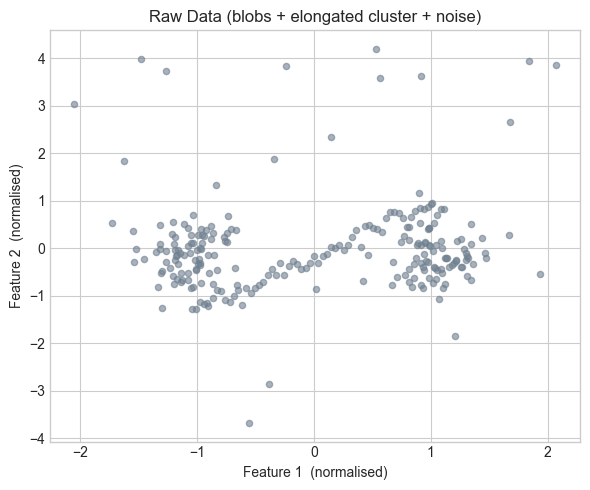

In [3]:
# Normalise
mu_X    = X.mean(axis=0)
sigma_X = X.std(axis=0)
sigma_X[sigma_X == 0] = 1
X_n = (X - mu_X) / sigma_X

plt.figure(figsize=(6, 5))
plt.scatter(X_n[:, 0], X_n[:, 1], alpha=0.6, s=20, color='slategray')
plt.title('Raw Data (blobs + elongated cluster + noise)')
plt.xlabel('Feature 1  (normalised)')
plt.ylabel('Feature 2  (normalised)')
plt.tight_layout()
plt.show()

## 5. Distance Matrix

In [4]:
def compute_distance_matrix(X):
    """
    Compute pairwise Euclidean distance matrix.

    D[i, j] = ||x^(i) - x^(j)||_2

    Returns
    -------
    D : ndarray (m, m)
    """
    m = X.shape[0]
    D = np.zeros((m, m))
    for i in range(m):
        diff     = X - X[i]              # broadcast: shape (m, n)
        D[i, :] = np.sqrt(np.sum(diff ** 2, axis=1))
    return D

D = compute_distance_matrix(X_n)
print(f"Distance matrix shape: {D.shape}")

Distance matrix shape: (240, 240)


## 6. ε-Neighbourhood Query

In [5]:
def get_neighbours(i, D, eps):
    """
    Return indices of all points within distance eps from point i
    (including point i itself).
    """
    return np.where(D[i] <= eps)[0]

## 7. DBSCAN — Main Algorithm

In [6]:
def dbscan(X, eps, min_samples):
    """
    DBSCAN clustering.

    Parameters
    ----------
    X           : ndarray (m, n)
    eps         : float — neighbourhood radius
    min_samples : int   — minimum neighbours to be a core point

    Returns
    -------
    labels : ndarray (m,) — cluster label per point;
             -1 means noise, 0/1/2/... are cluster IDs
    """
    m      = X.shape[0]
    D      = compute_distance_matrix(X)
    labels = np.full(m, -1, dtype=int)    # -1 = unclassified / noise
    visited = np.zeros(m, dtype=bool)

    cluster_id = 0

    for i in range(m):
        if visited[i]:
            continue
        visited[i] = True

        neighbours = get_neighbours(i, D, eps)

        if len(neighbours) < min_samples:
            labels[i] = -1    # noise (may be upgraded to border later)
            continue

        # i is a core point — start a new cluster
        labels[i] = cluster_id

        # BFS expansion: process all reachable points
        queue = list(neighbours)
        while queue:
            j = queue.pop(0)

            if labels[j] == -1:
                labels[j] = cluster_id    # border point upgraded

            if visited[j]:
                continue
            visited[j] = True
            labels[j]  = cluster_id

            j_neighbours = get_neighbours(j, D, eps)
            if len(j_neighbours) >= min_samples:
                # j is also a core point — expand from j
                queue.extend(j_neighbours)

        cluster_id += 1

    return labels

## 8. Run DBSCAN

In [7]:
eps         = 0.4
min_samples = 5

labels = dbscan(X_n, eps=eps, min_samples=min_samples)

n_clusters = len(np.unique(labels[labels != -1]))
n_noise    = np.sum(labels == -1)

print(f"Clusters found : {n_clusters}")
print(f"Noise points   : {n_noise}")
print(f"Cluster labels : {np.unique(labels)}")

Clusters found : 1
Noise points   : 18
Cluster labels : [-1  0]


## 9. Visualisation

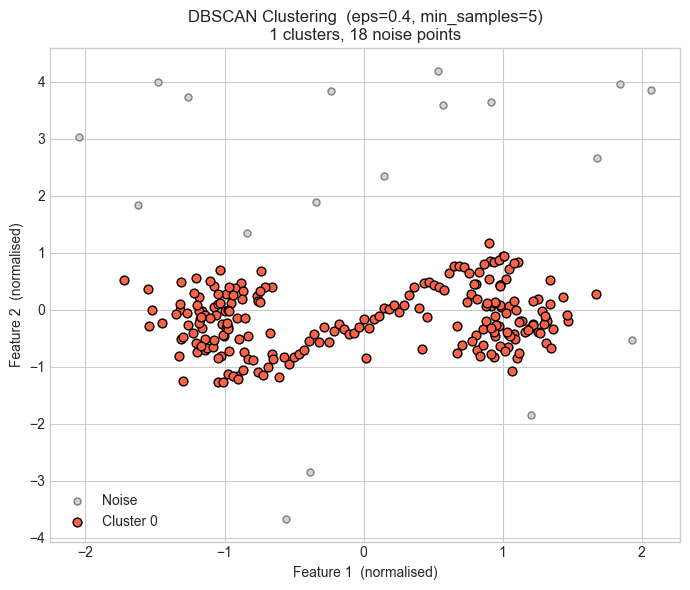

In [8]:
palette = ['tomato', 'steelblue', 'seagreen', 'goldenrod', 'mediumpurple', 'darkorange']

fig, ax = plt.subplots(figsize=(7, 6))

# Plot noise first (behind clusters)
noise_mask = labels == -1
ax.scatter(X_n[noise_mask, 0], X_n[noise_mask, 1],
           color='lightgray', edgecolors='gray', s=25, label='Noise', zorder=1)

# Plot each cluster
for k in range(n_clusters):
    mask = labels == k
    ax.scatter(X_n[mask, 0], X_n[mask, 1],
               color=palette[k % len(palette)], edgecolors='k',
               s=40, label=f'Cluster {k}', zorder=2)

ax.set_xlabel('Feature 1  (normalised)')
ax.set_ylabel('Feature 2  (normalised)')
ax.set_title(f'DBSCAN Clustering  (eps={eps}, min_samples={min_samples})\n'
             f'{n_clusters} clusters, {n_noise} noise points')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Effect of eps on Clustering

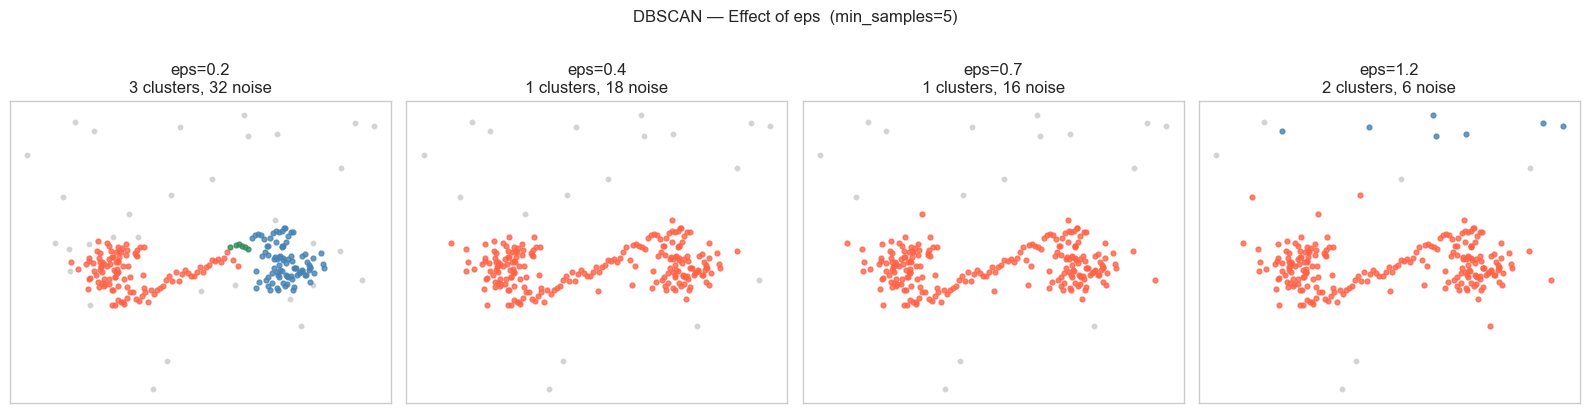

In [9]:
eps_values = [0.2, 0.4, 0.7, 1.2]
fig, axes  = plt.subplots(1, 4, figsize=(16, 4))

for ax, ep in zip(axes, eps_values):
    lbl = dbscan(X_n, eps=ep, min_samples=5)
    nc  = len(np.unique(lbl[lbl != -1]))
    nn  = np.sum(lbl == -1)

    # Noise
    nm = lbl == -1
    ax.scatter(X_n[nm, 0], X_n[nm, 1], color='lightgray', s=10, label='noise')
    for k in range(nc):
        km = lbl == k
        ax.scatter(X_n[km, 0], X_n[km, 1],
                   color=palette[k % len(palette)], s=12, alpha=0.8)
    ax.set_title(f'eps={ep}\n{nc} clusters, {nn} noise')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('DBSCAN — Effect of eps  (min_samples=5)', y=1.02)
plt.tight_layout()
plt.show()

## 11. k-Distance Plot — Heuristic for eps Selection

Sort points by their distance to their $k$-th nearest neighbour (here $k$ = `min_samples`). The "elbow" in this plot suggests a good value of `eps`.

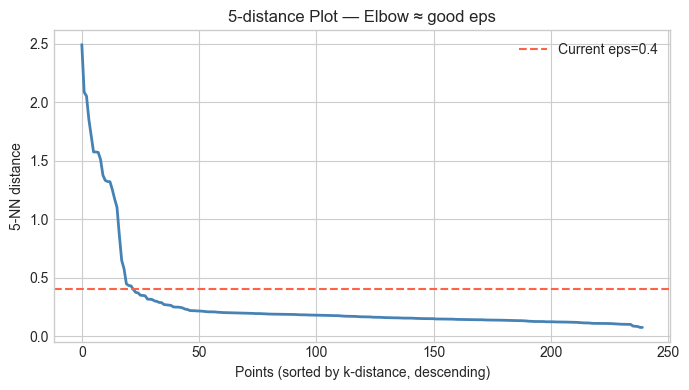

In [10]:
k_nn = min_samples

# kth-nearest-neighbour distances
kth_distances = np.sort(D, axis=1)[:, k_nn]   # column k_nn = (k_nn+1)-th closest
kth_sorted    = np.sort(kth_distances)[::-1]   # descending

plt.figure(figsize=(7, 4))
plt.plot(kth_sorted, color='steelblue', linewidth=2)
plt.axhline(eps, color='tomato', linestyle='--', linewidth=1.5,
            label=f'Current eps={eps}')
plt.xlabel('Points (sorted by k-distance, descending)')
plt.ylabel(f'{k_nn}-NN distance')
plt.title(f'{k_nn}-distance Plot — Elbow ≈ good eps')
plt.legend()
plt.tight_layout()
plt.show()

## 12. Evaluation — Cluster Purity (using synthetic labels)

In [11]:
# We know the first 160 points are blob-cluster data, next 60 are line, next 20 are noise
# Just print cluster composition as a sanity check
print("Cluster composition (indices 0-159 = blobs, 160-219 = line, 220-239 = noise):")
for k in np.unique(labels):
    pts_idx = np.where(labels == k)[0]
    label_name = f'Cluster {k}' if k >= 0 else 'Noise'
    print(f"  {label_name:12s}: {len(pts_idx):3d} points | "
          f"blob-pts={np.sum(pts_idx < 160):3d}  "
          f"line-pts={np.sum((pts_idx >= 160) & (pts_idx < 220)):3d}  "
          f"noise-pts={np.sum(pts_idx >= 220):3d}")

Cluster composition (indices 0-159 = blobs, 160-219 = line, 220-239 = noise):
  Noise       :  18 points | blob-pts=  1  line-pts=  0  noise-pts= 17
  Cluster 0   : 222 points | blob-pts=159  line-pts= 60  noise-pts=  3


## 13. Observations and Limitations

### What we observed
- DBSCAN finds clusters of arbitrary shape (blobs and the elongated line).
- Noise points (random scatter) are correctly identified and labelled $-1$.
- The number of clusters is discovered automatically — no K needed.
- The k-distance plot gives a visual guide to choosing `eps`.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Two hyper-parameters** | `eps` and `min_samples` must be tuned; poor choices merge or split clusters. |
| **Varying densities** | DBSCAN struggles when clusters have very different densities (HDBSCAN addresses this). |
| **High dimensionality** | Euclidean distance becomes less meaningful; all distances converge. |
| **Slow for large data** | $O(m^2)$ distance matrix; needs spatial indexing (k-d tree) for large $m$. |
| **No centroids** | Cannot assign new test points to clusters without re-running. |
